## Weather API + Join, Q3 Weather Correlation, Chart (Mohamed)

Uses Mouad's cleaning functions from `team_notebook.ipynb` (cells 1-2) so this notebook runs on its own.

In [1]:
import json, time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Reuse the team cleaning code (defines `clean`, `clean_transactions`, `find_data`, ...)
team_nb = json.load(open(Path.cwd().parent / "team_notebook.ipynb")) if (Path.cwd().parent / "team_notebook.ipynb").exists() else json.load(open(Path.cwd() / "notebooks" / "team_notebook.ipynb"))
for i in (1, 2):
    exec("".join(team_nb["cells"][i]["source"]))

/Users/mohamedh__/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Original transactions: 25562
Store reference rows: 14
Original transactions: 25562
Cleaned transactions: 25532
Rows removed: 30
Unique cleaned stores: 12
Original category labels: 37
Cleaned category labels: 10

Cleaning decision log:


,dataset,step,before,after,affected
0,transactions,Remove exact duplicates,25562,25532,30
1,transactions,Standardize store IDs,25532,25532,4345
2,transactions,Parse nonmissing timestamps,25532,25532,24648
3,transactions,Flag missing / unparseable timestamps,25532,25532,884
4,transactions,Create daily date keys,25532,25532,24648
5,transactions,Clean formatted unit prices,25532,25532,4329
6,transactions,Flag missing/unparseable unit prices,25532,25532,0
7,transactions,Flag negative quantities,25532,25532,130
8,transactions,Flag missing/unparseable quantities,25532,25532,0
9,transactions,Standardize SKU formatting,25532,25532,0



All initial cleaning checks passed!

First sales date: 2024-09-01
Last sales date: 2024-09-30
Peak daily order date: 2024-09-14
Peak daily transaction records: 2007


### 1. One working weather API call

Open-Meteo archive API, daily precipitation and max wind for Orlando. It has a timeout, retries on 429/5xx with backoff, converts `time` to a datetime named `date` inside the function, and adds a `source` column.

**Timezone:** weather is requested with `timezone=America/New_York`, so each `date` is a local calendar day. Sales timestamps have no timezone, so we cut them to midnight (`.dt.normalize()`, done in the cleaning step as `date`) and merge on `date`.

**Decision (document in the decision log):** one location (Orlando, 28.54, -81.38) for the whole state. Fewer calls and simpler, but it ignores local weather at the other 11 stores.

In [2]:
BASE = "https://archive-api.open-meteo.com/v1/archive"
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {"latitude": lat, "longitude": lon, "start_date": start, "end_date": end,
              "daily": "precipitation_sum,windspeed_10m_max", "timezone": "America/New_York"}
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
        frame = pd.DataFrame(r.json()["daily"]).rename(columns={"time": "date"})
        frame["date"] = pd.to_datetime(frame["date"])
        frame["source"] = "open-meteo"
        return frame

weather = daily_weather("2024-09-01", "2024-09-30")
print("weather_api_rows:", len(weather), "| source:", weather["source"].iloc[0])
weather.head()

weather_api_rows: 30 | source: open-meteo


,date,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,3.0,18.8,open-meteo
1,2024-09-02,12.4,13.5,open-meteo
2,2024-09-03,24.8,22.8,open-meteo
3,2024-09-04,22.1,15.5,open-meteo
4,2024-09-05,22.7,15.2,open-meteo


### 2. Join weather to daily orders (validated)

Left join from sales so no sales day disappears, with `indicator=True` and asserts on row count, `right_only`, and the orders total. Rows with no timestamp (884) cannot be placed on a day, so they are excluded from the daily series and logged.

In [3]:
dated = clean.dropna(subset=["date"])
daily = dated.groupby("date").size().rename("orders").reset_index()
print("undated rows excluded from daily series:", clean["date"].isna().sum())

merged = daily.merge(weather, on="date", how="left", indicator=True)
assert len(merged) == len(daily), "the join changed the row count"
assert not (merged["_merge"] == "right_only").any()
assert merged["orders"].sum() == daily["orders"].sum(), "orders total changed"
print(merged["_merge"].value_counts().to_string())
print("sales days with no weather:", (merged["_merge"] == "left_only").sum())
merged.head()

undated rows excluded from daily series: 884
both          30
left_only      0
right_only     0
sales days with no weather: 0


,date,orders,precipitation_sum,windspeed_10m_max,source,_merge
0,2024-09-01,587,3.0,18.8,open-meteo,both
1,2024-09-02,580,12.4,13.5,open-meteo,both
2,2024-09-03,586,24.8,22.8,open-meteo,both
3,2024-09-04,566,22.1,15.5,open-meteo,both
4,2024-09-05,809,22.7,15.2,open-meteo,both


### 3. Q3: weather correlation and lag

Same-day correlation first, then orders against wind *k* days later. Correlations use all days in the range (n shown), not a 3-day window, because three points can produce any correlation.

In [4]:
LANDFALL = pd.Timestamp("2024-09-26")
n = len(merged)
print("n days:", n)
for k in range(0, 5):
    r = merged["orders"].corr(merged["windspeed_10m_max"].shift(-k))
    print(f"orders vs wind {k} day(s) later:  r = {r:.2f}")
peak_day = merged.loc[merged["orders"].idxmax(), "date"].date()
print("peak order day:", peak_day, "| landfall:", LANDFALL.date())

n days: 30
orders vs wind 0 day(s) later:  r = -0.24
orders vs wind 1 day(s) later:  r = -0.29
orders vs wind 2 day(s) later:  r = -0.33
orders vs wind 3 day(s) later:  r = -0.30
orders vs wind 4 day(s) later:  r = -0.30
peak order day: 2024-09-14 | landfall: 2024-09-26


### 4. Chart

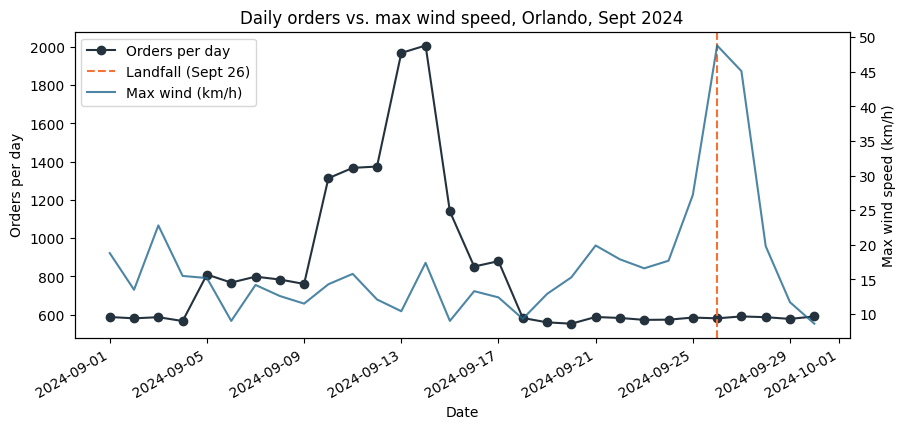

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(merged["date"], merged["orders"], marker="o", color="#24323E", label="Orders per day")
ax.axvline(LANDFALL, color="#F67132", linestyle="--", label="Landfall (Sept 26)")
ax.set_xlabel("Date"); ax.set_ylabel("Orders per day")
ax2 = ax.twinx()
ax2.plot(merged["date"], merged["windspeed_10m_max"], color="#21688D", alpha=0.8, label="Max wind (km/h)")
ax2.set_ylabel("Max wind speed (km/h)")
ax.set_title("Daily orders vs. max wind speed, Orlando, Sept 2024")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")
fig.autofmt_xdate(); plt.show()